<a href="https://colab.research.google.com/github/arambhaghimirecs24-stack/BIS/blob/main/1BF24CS062_Cuckoo_Search_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best Solution: [-2.17589422e-03  2.63022880e-03  3.48956936e-03 -5.23900841e-04
 -2.87398766e-05]
Best Fitness: 2.410501159853154e-05


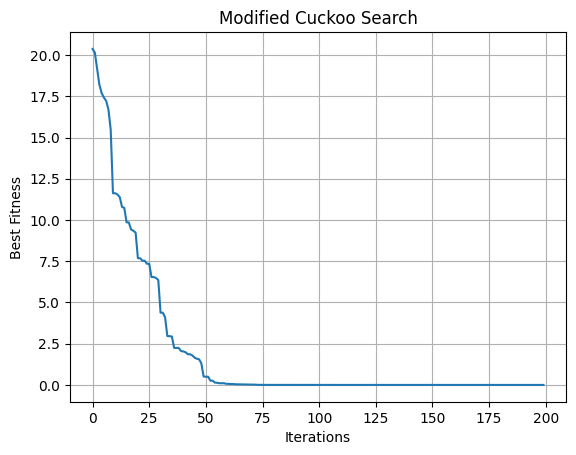

In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(10)

def fitness(x):
    return np.sum(x ** 2)

def MCS():

    N = 25
    dim = 5
    iterations = 200

    alpha = 0.01
    Pa = 0.25
    cr = 0.45

    lower = -10
    upper = 10

    nests = np.random.uniform(lower, upper, (N, dim))
    values = np.array([fitness(x) for x in nests])

    best = nests[np.argmin(values)].copy()
    best_value = min(values)

    history = []

    for t in range(iterations):

        for i in range(N):

            if np.random.rand() < cr:

                new = nests[i] + alpha * np.random.standard_cauchy(dim)

            else:

                r1, r2 = np.random.choice(
                    [j for j in range(N) if j != i],
                    2, replace=False
                )

                c1 = (0.5 + np.random.rand()) / 2
                c2 = (0.5 + np.random.rand()) / 2

                G1 = np.random.randn(dim)
                G2 = np.random.randn(dim)

                new = nests[i] + alpha * (
                    c1 * (nests[i] - best) * G1
                    + c2 * (nests[r1] - nests[r2]) * G2
                )

            new = np.clip(new, lower, upper)
            new_value = fitness(new)

            j = np.random.randint(N)

            if new_value < values[j]:
                nests[j] = new
                values[j] = new_value

        # Replace worst nests
        count = int(Pa * N)
        worst = np.argsort(values)[-count:]

        for j in worst:
            nests[j] = np.random.uniform(lower, upper, dim)
            values[j] = fitness(nests[j])

        # Update best solution
        index = np.argmin(values)

        if values[index] < best_value:
            best = nests[index].copy()
            best_value = values[index]

        history.append(best_value)

    return best, best_value, history


best, value, history = MCS()

print("Best Solution:", best)
print("Best Fitness:", value)

plt.plot(history)
plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("Modified Cuckoo Search")
plt.grid()
plt.show()